In [1]:
from pathlib import Path
import os
import sys
import json
import csv

ROOT = Path.cwd()
if not (ROOT / "data" / "manifests").exists():
    ROOT = Path(r"D:\\FILE AND TASK\\TA")
assert (ROOT / "data" / "manifests").exists(), ROOT
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ["MPLBACKEND"] = "Agg"

try:
    from IPython.display import display, Image
except ImportError:
    def display(item): print(item)
    class Image:
        def __init__(self, filename): self.filename = filename

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Project:", ROOT)
print("Kernel:", sys.executable)


def show_json(path):
    print(path)
    print(json.dumps(json.loads(path.read_text(encoding="utf-8")), ensure_ascii=False, indent=2))


def show_csv(path, rows=30):
    frame = pd.read_csv(path, low_memory=False)
    print(path, "|", len(frame), "baris")
    display(frame if len(frame) <= rows else pd.concat([frame.head(rows // 2), frame.tail(rows // 2)]))
    if len(frame) > rows:
        print("Tampilan adalah sampel; CSV lengkap tetap berada di path di atas.")
    return frame


Project: D:\FILE AND TASK\TA
Kernel: c:\Users\Fabio\AppData\Local\Programs\Python\Python314\python.exe


In [2]:
# Kode eksperimen berasal dari scripts/run_e2_controlled_noise.py dan ditempatkan langsung di notebook ini.
# Tidak ada pemanggilan subprocess atau eksekusi file runner eksternal.
# Entry point CLI sengaja tidak dipanggil otomatis agar artefak valid tidak tertimpa.
__file__ = str(ROOT / "scripts" / "run_e2_controlled_noise.py")

"""Run E2: controlled ITERA-noise robustness for R0--R3.

The runner writes only a new, timestamped directory under
``results/reproductions``.  Gallery vectors are loaded from verified clean
caches; only noisy query vectors are extracted.  Each completed condition is
published atomically and is validated before a resumed run may reuse it.
"""


import argparse
import hashlib
import json
import os
import subprocess
import sys
from datetime import datetime, timezone
from pathlib import Path

os.environ["MPLBACKEND"] = "Agg"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path(__file__).resolve().parent.parent
sys.path.insert(0, str(ROOT))

from src.embeddings import AudioRepresentationExtractor, R3_CONTROL_VERSION
from src.mix_noise import mix_audio_at_snr
from src.preprocess import preprocess_audio
from src.retrieve import compute_query_retrieval, evaluate_retrieval_corpus

MANIFEST = ROOT / "data" / "manifests" / "dataset_split.csv"
FEATURES = ROOT / "results" / "features"
OUTPUT_ROOT = ROOT / "results" / "reproductions"
REPRESENTATIONS = ("R0", "R1", "R2", "R3")
SNR_LEVELS = (20, 10, 0, -5)
DIMENSIONS = {"R0": 40, "R1": 2048, "R2": 1024, "R3": 40}
NOISE_SEED_BASE = 20_261_012


def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as source:
        for chunk in iter(lambda: source.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def json_hash(value: object) -> str:
    return hashlib.sha256(
        json.dumps(value, ensure_ascii=False, sort_keys=True, separators=(",", ":")).encode("utf-8")
    ).hexdigest()


def git_sha() -> str | None:
    try:
        return subprocess.check_output(
            ["git", "rev-parse", "HEAD"], cwd=ROOT, text=True, stderr=subprocess.DEVNULL
        ).strip()
    except (OSError, subprocess.CalledProcessError):
        return None


def atomic_json(path: Path, value: object, replace: bool = False) -> None:
    if path.exists() and not replace:
        raise FileExistsError(f"Refusing to overwrite existing file: {path}")
    temporary = path.with_name(path.name + ".tmp")
    if temporary.exists():
        raise FileExistsError(f"Temporary file requires review: {temporary}")
    payload = (json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False) + "\n").encode("utf-8")
    with temporary.open("xb") as output:
        output.write(payload)
        output.flush()
        os.fsync(output.fileno())
    temporary.replace(path)


def atomic_csv(frame: pd.DataFrame, path: Path) -> None:
    if path.exists():
        raise FileExistsError(f"Refusing to overwrite existing condition: {path}")
    temporary = path.with_name(path.name + ".tmp")
    if temporary.exists():
        raise FileExistsError(f"Temporary file requires review: {temporary}")
    with temporary.open("x", newline="", encoding="utf-8") as output:
        frame.to_csv(output, index=False)
        output.flush()
        os.fsync(output.fileno())
    temporary.replace(path)


def load_active_split() -> tuple[pd.DataFrame, pd.DataFrame]:
    manifest = pd.read_csv(MANIFEST, dtype={"recording_id": str})
    gallery = manifest.loc[manifest["split_role"].eq("gallery")].reset_index(drop=True)
    queries = manifest.loc[manifest["split_role"].eq("query_clean")].reset_index(drop=True)
    if len(gallery) != 673 or len(queries) != 311:
        raise ValueError(f"Active split mismatch: gallery={len(gallery)}, query={len(queries)}")
    for name, frame in {"gallery": gallery, "query": queries}.items():
        if frame["recording_id"].duplicated().any() or frame["file_path"].duplicated().any():
            raise ValueError(f"Duplicate ID or path in {name} split.")
    return gallery, queries


def load_cache(rep: str, gallery: pd.DataFrame, queries: pd.DataFrame) -> tuple[Path, dict[str, np.ndarray]]:
    path = FEATURES / f"clean_embeddings_{rep}.npz"
    if not path.is_file():
        raise FileNotFoundError(f"Clean cache not found: {path}")
    with np.load(path) as source:
        mandatory = {"gal_feats", "qry_feats", "gal_ids", "qry_ids", "manifest_sha256"}
        missing = mandatory.difference(source.files)
        if missing:
            raise ValueError(f"Cache {rep} missing: {sorted(missing)}")
        cache = {key: source[key].copy() for key in source.files}
    if str(cache["manifest_sha256"].item()) != sha256_file(MANIFEST):
        raise ValueError(f"Cache {rep} uses a different manifest.")
    if cache["gal_feats"].shape != (len(gallery), DIMENSIONS[rep]):
        raise ValueError(f"Gallery cache shape invalid for {rep}: {cache['gal_feats'].shape}")
    if cache["qry_feats"].shape != (len(queries), DIMENSIONS[rep]):
        raise ValueError(f"Query cache shape invalid for {rep}: {cache['qry_feats'].shape}")
    if not np.array_equal(cache["gal_ids"].astype(str), gallery["recording_id"].astype(str).to_numpy()):
        raise ValueError(f"Gallery IDs in {rep} cache do not match active manifest.")
    if not np.array_equal(cache["qry_ids"].astype(str), queries["recording_id"].astype(str).to_numpy()):
        raise ValueError(f"Query IDs in {rep} cache do not match active manifest.")
    if not np.isfinite(cache["gal_feats"]).all() or not np.isfinite(cache["qry_feats"]).all():
        raise ValueError(f"Non-finite embedding found in {rep} cache.")
    if rep == "R3":
        version = str(cache.get("r3_control_version", np.array("missing")).item())
        if version != R3_CONTROL_VERSION:
            raise ValueError(f"R3 cache version {version} is not {R3_CONTROL_VERSION}.")
    return path, cache


def build_identity(cache_paths: dict[str, Path]) -> dict:
    assets = {
        "dataset_manifest": {"path": str(MANIFEST.relative_to(ROOT)).replace("\\", "/"), "sha256": sha256_file(MANIFEST)},
        "preprocess": {"path": "src/preprocess.py", "sha256": sha256_file(ROOT / "src" / "preprocess.py")},
        "mix_noise": {"path": "src/mix_noise.py", "sha256": sha256_file(ROOT / "src" / "mix_noise.py")},
        "embeddings": {"path": "src/embeddings.py", "sha256": sha256_file(ROOT / "src" / "embeddings.py")},
        "retrieval": {"path": "src/retrieve.py", "sha256": sha256_file(ROOT / "src" / "retrieve.py")},
    }
    for rep, path in cache_paths.items():
        assets[f"{rep}_cache"] = {"path": str(path.relative_to(ROOT)).replace("\\", "/"), "sha256": sha256_file(path)}
    for rep, checkpoint in {
        "R1": ROOT / "checkpoints" / "Cnn14_mAP=0.431.pth",
        "R2": ROOT / "checkpoints" / "BirdNET_GLOBAL_6K_V2.4_Model_FP32.onnx",
    }.items():
        if not checkpoint.is_file():
            raise FileNotFoundError(checkpoint)
        assets[f"{rep}_checkpoint"] = {"path": str(checkpoint.relative_to(ROOT)).replace("\\", "/"), "sha256": sha256_file(checkpoint)}
    identity = {
        "schema": "e2_controlled_noise_v1",
        "assets": assets,
        "design": {
            "representations": list(REPRESENTATIONS),
            "snr_db": list(SNR_LEVELS),
            "n_gallery": 673,
            "n_query": 311,
            "noise_seed_base": NOISE_SEED_BASE,
            "noise_seed_rule": "20261012 + query_index (same segment across SNR and representation)",
            "e3_reserved_noise_excluded": True,
            "r3_control_version": R3_CONTROL_VERSION,
        },
    }
    return {"identity": identity, "sha256": json_hash(identity)}


def validate_existing_condition(path: Path, queries: pd.DataFrame, rep: str, snr: int) -> pd.DataFrame:
    sidecar = path.with_suffix(".json")
    if not sidecar.is_file():
        raise ValueError(f"Condition CSV has no completed sidecar: {path}")
    frame = pd.read_csv(path, low_memory=False)
    required = {
        "query_id", "species_key", "representation", "condition", "snr_db", "noise_file",
        "noise_seed", "snr_db_target", "snr_db_achieved", "max_score", "top1_match", "AP@10",
    }
    if missing := required.difference(frame.columns):
        raise ValueError(f"Condition {path} lacks columns: {sorted(missing)}")
    if len(frame) != len(queries) or frame["query_id"].astype(str).tolist() != queries["recording_id"].astype(str).tolist():
        raise ValueError(f"Condition {path} does not align with active queries.")
    if set(frame["representation"].astype(str)) != {rep} or set(frame["snr_db"].astype(int)) != {snr}:
        raise ValueError(f"Condition {path} identity mismatch.")
    required_finite = ["max_score", "AP@10"]
    if snr != 999:
        required_finite.append("snr_db_achieved")
    if not np.isfinite(frame[required_finite].to_numpy(dtype=float)).all():
        raise ValueError(f"Condition {path} contains non-finite scores or SNR.")
    return frame


def diagnostic_rows(
    vectors: np.ndarray,
    gallery_vectors: np.ndarray,
    gallery: pd.DataFrame,
    queries: pd.DataFrame,
    rep: str,
    condition: str,
    snr: int,
    mixes: list[dict] | None,
) -> pd.DataFrame:
    gallery_labels = gallery["species_key"].astype(str).tolist()
    normalized_gallery = gallery_vectors / np.maximum(np.linalg.norm(gallery_vectors, axis=1, keepdims=True), 1e-8)
    rows: list[dict] = []
    for index, (_, query) in enumerate(queries.iterrows()):
        vector = vectors[index]
        scores = normalized_gallery @ (vector / max(float(np.linalg.norm(vector)), 1e-8))
        rank = np.argsort(-scores, kind="stable")
        top_index = int(rank[0])
        target = str(query["species_key"])
        target_mask = gallery["species_key"].astype(str).to_numpy() == target
        metrics = compute_query_retrieval(vector, target, gallery_vectors, gallery_labels)
        row = {
            "query_id": str(query["recording_id"]),
            "species_key": target,
            "author": str(query["author"]),
            "representation": rep,
            "condition": condition,
            "snr_db": snr,
            "top1_recording_id": str(gallery.iloc[top_index]["recording_id"]),
            "top1_species_key": str(gallery.iloc[top_index]["species_key"]),
            "top1_similarity": float(scores[top_index]),
            "true_class_max_similarity": float(np.max(scores[target_mask])),
            "best_other_similarity": float(np.max(scores[~target_mask])),
        }
        row["true_vs_other_margin"] = row["true_class_max_similarity"] - row["best_other_similarity"]
        row.update(metrics)
        if mixes is None:
            row.update({
                "noise_file": "None (Clean)", "noise_seed": np.nan, "noise_start_sample": np.nan,
                "noise_segment_samples": np.nan, "noise_attempt": np.nan, "noise_raw_rms": np.nan,
                "snr_db_target": np.nan, "snr_db_achieved": np.nan, "noise_gain": np.nan,
                "post_mix_gain": np.nan, "mix_skipped_silent_signal": False,
            })
        else:
            row.update(mixes[index])
        rows.append(row)
    return pd.DataFrame(rows)


def summarize(frame: pd.DataFrame) -> dict[str, float]:
    return {
        "num_queries": int(len(frame)),
        "Top1_Accuracy": float(frame["top1_match"].mean()),
        "MRR": float(frame["RR"].mean()),
        "mAP@10": float(frame["AP@10"].mean()),
        "Recall@10": float(frame["R@10"].mean()),
        "Precision@10": float(frame["P@10"].mean()),
    }


def write_condition(path: Path, frame: pd.DataFrame, identity_hash: str, summary: dict[str, float]) -> None:
    atomic_csv(frame, path)
    atomic_json(path.with_suffix(".json"), {
        "schema": "e2_condition_v1", "run_identity_sha256": identity_hash,
        "rows": int(len(frame)), "summary": summary,
    })


def make_figure(table: pd.DataFrame, output: Path) -> None:
    plt.figure(figsize=(8, 5))
    for rep, part in table.groupby("representation", sort=True):
        noisy = part.loc[part["condition"].ne("Clean")].sort_values("snr_db")
        plt.plot(noisy["snr_db"], noisy["mAP@10"], marker="o", label=rep)
    plt.xlabel("Target SNR (dB)")
    plt.ylabel("mAP@10")
    plt.title("E2 controlled ITERA-noise robustness")
    plt.grid(alpha=0.3)
    plt.legend(title="Representation")
    plt.tight_layout()
    plt.savefig(output, dpi=180)
    plt.close()


def execute(run_dir: Path, resume: bool) -> Path:
    gallery, queries = load_active_split()
    caches: dict[str, dict[str, np.ndarray]] = {}
    cache_paths: dict[str, Path] = {}
    for rep in REPRESENTATIONS:
        cache_paths[rep], caches[rep] = load_cache(rep, gallery, queries)
    identity = build_identity(cache_paths)
    identity_path = run_dir / "run_identity.json"

    if resume:
        if not identity_path.is_file():
            raise FileNotFoundError(f"Cannot resume without identity: {identity_path}")
        stored = json.loads(identity_path.read_text(encoding="utf-8"))
        if stored != identity:
            raise ValueError("Resume refused: input assets or design changed.")
    else:
        if run_dir.exists():
            raise FileExistsError(f"Run directory exists: {run_dir}")
        (run_dir / "raw").mkdir(parents=True)
        (run_dir / "tables").mkdir()
        (run_dir / "figures").mkdir()
        atomic_json(identity_path, identity)
        atomic_json(run_dir / "metadata.json", {
            "artifact_schema": "e2_controlled_noise_v1", "status": "running",
            "started_utc": datetime.now(timezone.utc).isoformat(), "git_sha": git_sha(),
            "run_identity_sha256": identity["sha256"],
        })

    clean_audio = [preprocess_audio(str(row["file_path"])) for _, row in queries.iterrows()]
    all_summaries: list[dict] = []
    for rep in REPRESENTATIONS:
        cache = caches[rep]
        gallery_vectors = cache["gal_feats"]
        clean_path = run_dir / "raw" / f"{rep}_Clean.csv"
        if clean_path.is_file():
            clean_frame = validate_existing_condition(clean_path, queries, rep, 999)
        else:
            clean_frame = diagnostic_rows(cache["qry_feats"], gallery_vectors, gallery, queries, rep, "Clean", 999, None)
            write_condition(clean_path, clean_frame, identity["sha256"], summarize(clean_frame))
        clean_summary = summarize(clean_frame)
        clean_summary.update({"representation": rep, "condition": "Clean", "snr_db": 999, "relative_retention": 1.0})
        all_summaries.append(clean_summary)

        extractor = None if rep == "R0" else AudioRepresentationExtractor(rep)
        if rep == "R0":
            extractor = AudioRepresentationExtractor("R0")
        for snr in SNR_LEVELS:
            path = run_dir / "raw" / f"{rep}_SNR_{snr}dB.csv"
            if path.is_file():
                frame = validate_existing_condition(path, queries, rep, snr)
            else:
                vectors: list[np.ndarray] = []
                mixes: list[dict] = []
                for index, clean in enumerate(clean_audio):
                    noisy, audit = mix_audio_at_snr(
                        clean, snr_db=snr, seed=NOISE_SEED_BASE + index, return_audit_info=True
                    )
                    embedding = extractor.extract(noisy, item_id=f"query_clean:{queries.iloc[index]['recording_id']}")
                    if embedding.shape != (DIMENSIONS[rep],) or not np.isfinite(embedding).all():
                        raise ValueError(f"Invalid {rep} embedding for {queries.iloc[index]['recording_id']}")
                    vectors.append(embedding.astype(np.float32, copy=False))
                    mixes.append(audit)
                    if (index + 1) % 50 == 0 or index + 1 == len(queries):
                        print(f"E2 {rep} SNR {snr}: {index + 1}/{len(queries)}", flush=True)
                frame = diagnostic_rows(np.stack(vectors), gallery_vectors, gallery, queries, rep, f"SNR_{snr}dB", snr, mixes)
                write_condition(path, frame, identity["sha256"], summarize(frame))
            summary = summarize(frame)
            summary.update({
                "representation": rep, "condition": f"SNR_{snr}dB", "snr_db": snr,
                "relative_retention": float(summary["mAP@10"] / clean_summary["mAP@10"]) if clean_summary["mAP@10"] else np.nan,
            })
            all_summaries.append(summary)

    table = pd.DataFrame(all_summaries).sort_values(["representation", "snr_db"], ascending=[True, False])
    table.to_csv(run_dir / "tables" / "e2_snr_robustness.csv", index=False)
    make_figure(table, run_dir / "figures" / "e2_snr_robustness_map10.png")
    validation = {
        "status": "PASS", "run_identity_sha256": identity["sha256"],
        "manifest_sha256": sha256_file(MANIFEST), "conditions": 20,
        "raw_rows": {path.name: int(len(pd.read_csv(path, low_memory=False))) for path in sorted((run_dir / "raw").glob("*.csv"))},
        "checks": ["cache_manifest", "cache_id_order", "finite_embeddings", "per_condition_query_ids", "snr_audit"],
    }
    atomic_json(run_dir / "validation_report.json", validation)
    atomic_json(run_dir / "metadata.json", {
        "artifact_schema": "e2_controlled_noise_v1", "status": "complete",
        "started_from_cache": True, "completed_utc": datetime.now(timezone.utc).isoformat(),
        "git_sha": git_sha(), "run_identity_sha256": identity["sha256"],
        "manifest_sha256": sha256_file(MANIFEST), "gallery_count": len(gallery), "query_count": len(queries),
        "representations": list(REPRESENTATIONS), "snr_db": list(SNR_LEVELS),
    }, replace=True)
    (run_dir / "README.md").write_text(
        "# E2 — Controlled ITERA-noise robustness\n\n"
        "Each `raw/*.csv` contains all 311 active queries for one representation and one condition. "
        "Gallery embeddings are the verified clean caches; noisy query embeddings are extracted with "
        "a deterministic physical-noise segment. Completed conditions can be resumed only after their "
        "CSV and sidecar JSON pass validation.\n",
        encoding="utf-8",
    )
    print(f"E2 complete: {run_dir}")
    return run_dir

print("Kode run_e2_controlled_noise.py telah dimuat di notebook. Jalankan fungsi eksperimen hanya jika memang ingin membuat run baru.")


Kode run_e2_controlled_noise.py telah dimuat di notebook. Jalankan fungsi eksperimen hanya jika memang ingin membuat run baru.


D:\FILE AND TASK\TA\results\reproductions\E2_controlled_20261012T021600_897497Z\validation_report.json
{
  "status": "PASS",
  "run_identity_sha256": "0379f6a773595151dcbac7362cfa1d7234cf4f5e1e88b45ee20720ab8b721a72",
  "manifest_sha256": "7808cdf057f135aaa193f47e27415318edf46c862c09dee4c7394bc5760e8ed8",
  "conditions": 20,
  "raw_rows": {
    "R0_Clean.csv": 311,
    "R0_SNR_-5dB.csv": 311,
    "R0_SNR_0dB.csv": 311,
    "R0_SNR_10dB.csv": 311,
    "R0_SNR_20dB.csv": 311,
    "R1_Clean.csv": 311,
    "R1_SNR_-5dB.csv": 311,
    "R1_SNR_0dB.csv": 311,
    "R1_SNR_10dB.csv": 311,
    "R1_SNR_20dB.csv": 311,
    "R2_Clean.csv": 311,
    "R2_SNR_-5dB.csv": 311,
    "R2_SNR_0dB.csv": 311,
    "R2_SNR_10dB.csv": 311,
    "R2_SNR_20dB.csv": 311,
    "R3_Clean.csv": 311,
    "R3_SNR_-5dB.csv": 311,
    "R3_SNR_0dB.csv": 311,
    "R3_SNR_10dB.csv": 311,
    "R3_SNR_20dB.csv": 311
  },
  "checks": [
    "cache_manifest",
    "cache_id_order",
    "finite_embeddings",
    "per_condition_query_i

,num_queries,Top1_Accuracy,MRR,mAP@10,Recall@10,Precision@10,representation,condition,snr_db,relative_retention
0,311,0.183280,0.310923,0.069393,0.036321,0.131190,R0,Clean,999,1.000000
1,311,0.196141,0.334154,0.076988,0.039478,0.141801,R0,SNR_20dB,20,1.109449
2,311,0.141479,0.259874,0.060414,0.032554,0.115756,R0,SNR_10dB,10,0.870608
3,311,0.080386,0.202847,0.032334,0.023583,0.077492,R0,SNR_0dB,0,0.465955
4,311,0.073955,0.184488,0.023210,0.019337,0.059164,R0,SNR_-5dB,-5,0.334473
5,311,0.376206,0.507048,0.176268,0.084175,0.258521,R1,Clean,999,1.000000
6,311,0.392283,0.514658,0.184900,0.082629,0.259486,R1,SNR_20dB,20,1.048973
7,311,0.360129,0.482440,0.172136,0.077801,0.248553,R1,SNR_10dB,10,0.976562
8,311,0.282958,0.400171,0.118796,0.053061,0.188424,R1,SNR_0dB,0,0.673953
9,311,0.225080,0.344643,0.086306,0.039470,0.148875,R1,SNR_-5dB,-5,0.489628


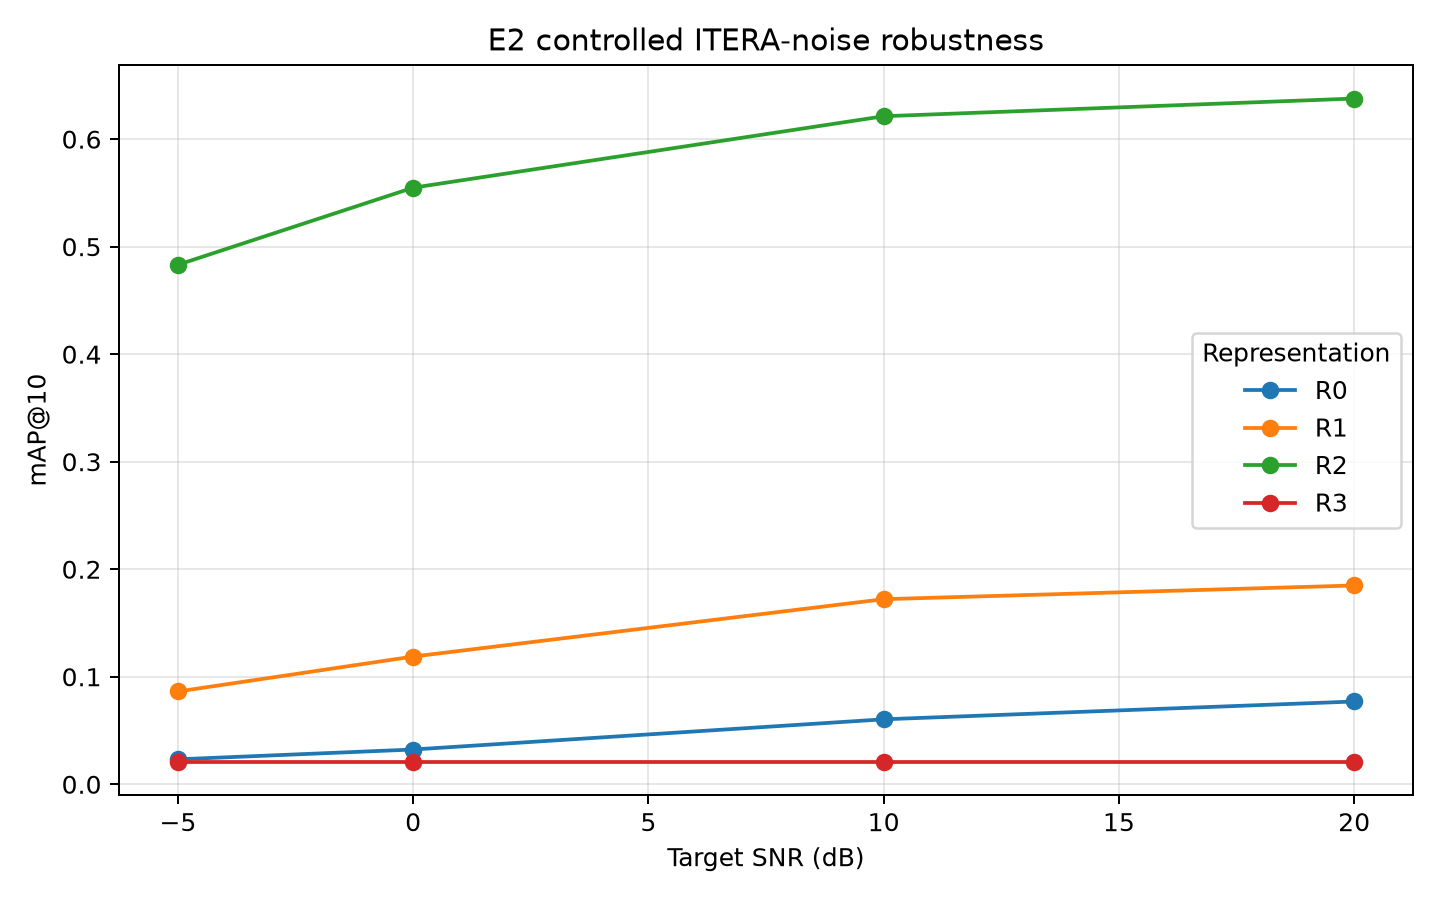

D:\FILE AND TASK\TA\results\reproductions\E2_controlled_20261012T021600_897497Z\raw\R0_Clean.csv | 311 baris


,query_id,species_key,author,representation,condition,snr_db,top1_recording_id,top1_species_key,top1_similarity,true_class_max_similarity,...,noise_seed,noise_start_sample,noise_segment_samples,noise_attempt,noise_raw_rms,snr_db_target,snr_db_achieved,noise_gain,post_mix_gain,mix_skipped_silent_signal
0,XC42472,savnig1,David Marques,R0,Clean,999,XC40064,savnig1,0.991959,0.991959,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
1,XC1098429,ashtai1,Yasinchumaedi,R0,Clean,999,XC932943,sohbul1,0.991454,0.973378,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
2,XC20097,ashtai1,Sander Pieterse & Ben Wielstra,R0,Clean,999,XC278707,lessho1,0.994453,0.984843,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
3,XC20098,ashtai1,Sander Pieterse & Ben Wielstra,R0,Clean,999,XC69233,pygcup1,0.992043,0.974640,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
4,XC214420,ashtai1,Paulo Alves,R0,Clean,999,XC576635,lessho1,0.996303,0.949161,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
5,XC236330,ashtai1,Paulo Alves,R0,Clean,999,XC576635,lessho1,0.985306,0.922852,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
305,XC681091,whbsho1,Mike Nelson,R0,Clean,999,XC576634,whbsho1,0.994650,0.994650,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
306,XC70338,whbsho1,David Gibbs,R0,Clean,999,XC67798,rubcuc1,0.986777,0.973986,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
307,XC70339,whbsho1,David Gibbs,R0,Clean,999,XC153017,sohbul1,0.993014,0.976652,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
308,XC70340,whbsho1,David Gibbs,R0,Clean,999,XC89270,moutai1,0.991131,0.989712,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False


Tampilan adalah sampel; CSV lengkap tetap berada di path di atas.
D:\FILE AND TASK\TA\results\reproductions\E2_controlled_20261012T021600_897497Z\raw\R1_SNR_-5dB.csv | 311 baris


,query_id,species_key,author,representation,condition,snr_db,top1_recording_id,top1_species_key,top1_similarity,true_class_max_similarity,...,noise_seed,noise_attempt,noise_raw_rms,snr_db_target,snr_db_achieved,signal_power,noise_power_before_scaling,noise_gain,post_mix_gain,mix_skipped_silent_signal
0,XC42472,savnig1,David Marques,R1,SNR_-5dB,-5,XC473999,ashtai1,0.833093,0.751862,...,20261012,1,0.017039,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False
1,XC1098429,ashtai1,Yasinchumaedi,R1,SNR_-5dB,-5,XC150446,savnig1,0.868916,0.815886,...,20261013,1,0.084434,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False
2,XC20097,ashtai1,Sander Pieterse & Ben Wielstra,R1,SNR_-5dB,-5,XC69232,pygcup1,0.915397,0.838521,...,20261014,1,0.009353,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False
3,XC20098,ashtai1,Sander Pieterse & Ben Wielstra,R1,SNR_-5dB,-5,XC145300,subwar1,0.889844,0.836115,...,20261015,1,0.020361,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False
4,XC214420,ashtai1,Paulo Alves,R1,SNR_-5dB,-5,XC200539,moutai1,0.930239,0.883308,...,20261016,1,0.052136,-5.0,-5.0,0.002498,0.0025,1.777686,0.985136,False
5,XC236330,ashtai1,Paulo Alves,R1,SNR_-5dB,-5,XC200542,moutai1,0.925384,0.819342,...,20261017,1,0.032680,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False
305,XC681091,whbsho1,Mike Nelson,R1,SNR_-5dB,-5,XC287077,lessho1,0.919796,0.889481,...,20261317,1,0.002329,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False
306,XC70338,whbsho1,David Gibbs,R1,SNR_-5dB,-5,XC38420,moutai1,0.906749,0.835825,...,20261318,1,0.021491,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False
307,XC70339,whbsho1,David Gibbs,R1,SNR_-5dB,-5,XC121823,colkin1,0.890688,0.759503,...,20261319,1,0.124470,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False
308,XC70340,whbsho1,David Gibbs,R1,SNR_-5dB,-5,XC445216,sohbul1,0.809286,0.719467,...,20261320,1,0.023809,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False


Tampilan adalah sampel; CSV lengkap tetap berada di path di atas.
D:\FILE AND TASK\TA\results\reproductions\E2_controlled_20261012T021600_897497Z\raw\R2_SNR_-5dB.csv | 311 baris


,query_id,species_key,author,representation,condition,snr_db,top1_recording_id,top1_species_key,top1_similarity,true_class_max_similarity,...,noise_seed,noise_attempt,noise_raw_rms,snr_db_target,snr_db_achieved,signal_power,noise_power_before_scaling,noise_gain,post_mix_gain,mix_skipped_silent_signal
0,XC42472,savnig1,David Marques,R2,SNR_-5dB,-5,XC954969,savnig1,0.765014,0.765014,...,20261012,1,0.017039,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False
1,XC1098429,ashtai1,Yasinchumaedi,R2,SNR_-5dB,-5,XC208015,ashtai1,0.614915,0.614915,...,20261013,1,0.084434,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False
2,XC20097,ashtai1,Sander Pieterse & Ben Wielstra,R2,SNR_-5dB,-5,XC168880,hoopit1,0.558547,0.546229,...,20261014,1,0.009353,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False
3,XC20098,ashtai1,Sander Pieterse & Ben Wielstra,R2,SNR_-5dB,-5,XC473999,ashtai1,0.625703,0.625703,...,20261015,1,0.020361,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False
4,XC214420,ashtai1,Paulo Alves,R2,SNR_-5dB,-5,XC331995,gpipig1,0.641580,0.588737,...,20261016,1,0.052136,-5.0,-5.0,0.002498,0.0025,1.777686,0.985136,False
5,XC236330,ashtai1,Paulo Alves,R2,SNR_-5dB,-5,XC168880,hoopit1,0.589199,0.581603,...,20261017,1,0.032680,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False
305,XC681091,whbsho1,Mike Nelson,R2,SNR_-5dB,-5,XC67742,whbsho1,0.678522,0.678522,...,20261317,1,0.002329,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False
306,XC70338,whbsho1,David Gibbs,R2,SNR_-5dB,-5,XC576634,whbsho1,0.685541,0.685541,...,20261318,1,0.021491,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False
307,XC70339,whbsho1,David Gibbs,R2,SNR_-5dB,-5,XC168880,hoopit1,0.599203,0.563727,...,20261319,1,0.124470,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False
308,XC70340,whbsho1,David Gibbs,R2,SNR_-5dB,-5,XC195596,whbsho1,0.651242,0.651242,...,20261320,1,0.023809,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False


Tampilan adalah sampel; CSV lengkap tetap berada di path di atas.
D:\FILE AND TASK\TA\results\reproductions\E2_controlled_20261012T021600_897497Z\raw\R3_SNR_-5dB.csv | 311 baris


,query_id,species_key,author,representation,condition,snr_db,top1_recording_id,top1_species_key,top1_similarity,true_class_max_similarity,...,noise_seed,noise_attempt,noise_raw_rms,snr_db_target,snr_db_achieved,signal_power,noise_power_before_scaling,noise_gain,post_mix_gain,mix_skipped_silent_signal
0,XC42472,savnig1,David Marques,R3,SNR_-5dB,-5,XC287770,subwar1,0.410280,0.168684,...,20261012,1,0.017039,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False
1,XC1098429,ashtai1,Yasinchumaedi,R3,SNR_-5dB,-5,XC67798,rubcuc1,0.497373,0.323404,...,20261013,1,0.084434,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False
2,XC20097,ashtai1,Sander Pieterse & Ben Wielstra,R3,SNR_-5dB,-5,XC255441,rubcuc1,0.496470,0.432224,...,20261014,1,0.009353,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False
3,XC20098,ashtai1,Sander Pieterse & Ben Wielstra,R3,SNR_-5dB,-5,XC596830,rubcuc1,0.456066,0.235471,...,20261015,1,0.020361,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False
4,XC214420,ashtai1,Paulo Alves,R3,SNR_-5dB,-5,XC746052,olbsun1,0.433755,0.317963,...,20261016,1,0.052136,-5.0,-5.0,0.002498,0.0025,1.777686,0.985136,False
5,XC236330,ashtai1,Paulo Alves,R3,SNR_-5dB,-5,XC1059449,colkin1,0.482709,0.225218,...,20261017,1,0.032680,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False
305,XC681091,whbsho1,Mike Nelson,R3,SNR_-5dB,-5,XC176898,hacdro1,0.492220,0.207626,...,20261317,1,0.002329,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False
306,XC70338,whbsho1,David Gibbs,R3,SNR_-5dB,-5,XC67810,rubcuc1,0.441239,0.227678,...,20261318,1,0.021491,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False
307,XC70339,whbsho1,David Gibbs,R3,SNR_-5dB,-5,XC68170,hacdro1,0.443217,0.351760,...,20261319,1,0.124470,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False
308,XC70340,whbsho1,David Gibbs,R3,SNR_-5dB,-5,XC1162378,moutai1,0.448376,0.208068,...,20261320,1,0.023809,-5.0,-5.0,0.002500,0.0025,1.778279,1.000000,False


Tampilan adalah sampel; CSV lengkap tetap berada di path di atas.
Semua 20 raw CSV per kondisi berada di: D:\FILE AND TASK\TA\results\reproductions\E2_controlled_20261012T021600_897497Z\raw


In [3]:
run = ROOT / "results/reproductions/E2_controlled_20261012T021600_897497Z"
show_json(run / "validation_report.json")
show_json(run / "metadata.json")
show_csv(run / "tables/e2_snr_robustness.csv")
display(Image(filename=str(run / "figures/e2_snr_robustness_map10.png")))
for name in ("R0_Clean.csv", "R1_SNR_-5dB.csv", "R2_SNR_-5dB.csv", "R3_SNR_-5dB.csv"):
    show_csv(run / "raw" / name, rows=12)
print("Semua 20 raw CSV per kondisi berada di:", run / "raw")
